# Global Solution 2026-2 — Citizen Intelligence & Predictive Analytics
## Clima, tempo e mobilidade urbana em São Paulo (2022–2023)

**Pergunta central:** como fatores climáticos e temporais influenciam (a) a severidade dos sinistros de trânsito e (b) a extensão dos congestionamentos na cidade de São Paulo?

**Fontes:**

| Fonte | Conteúdo | Grão original |
|---|---|---|
| INMET — estação A701 (Mirante de Santana) | precipitação, temperatura, umidade, vento, pressão | horário (UTC → convertido para local) |
| Infosiga-SP | sinistros com e sem vítimas, município de São Paulo | evento (data + hora) |
| CET | trechos em lentidão, com extensão em metros | instantâneos a cada 30 min |

Este notebook **não** reimplementa o pipeline: ele importa os módulos de `src/` (pré-processamento, indicadores e modelagem) e se concentra na análise exploratória, na leitura dos indicadores e na avaliação crítica dos modelos. Para regenerar as bases e os modelos, execute `make pipeline` na raiz do projeto.

In [1]:
import sys, json, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():  # notebook aberto a partir de notebooks/
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from src import config
from src.preprocessing import carregar_consolidado, carregar_horario
from src.features import (
    preparar_features, calcular_isr, calcular_frt, calcular_taxa_sinistros_por_clima,
    calcular_kpis_gerais, ORDEM_CHUVA, ORDEM_DIAS,
)
from src.modeling import (
    carregar_modelo, carregar_metadata, preparar_dados_classificacao, preparar_dados_regressao,
    FEATURES_CLASSIFICACAO, FEATURES_REGRESSAO, TEST_SIZE,
)
from src import viz

viz.aplicar_tema_seaborn()
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)
print("Projeto:", PROJECT_ROOT)

Projeto: /Users/joseneto/dev/studies/fiap/2CCPS/global-solution/cuidarplus-data-science-and-analytics


## 1. Carga das bases processadas

Duas tabelas saem da Etapa 1 (`src/preprocessing.py`):

* **`mobilidade_sp_consolidado.parquet`** — uma linha por sinistro, com o clima e a lentidão da hora em que ocorreu (alinhados com `pd.merge_asof`).
* **`mobilidade_sp_horario.parquet`** — grade horária completa (17.520 horas) com clima, lentidão e contagem de sinistros.

As features temporais (hora, dia da semana, feriado, hora de pico) e climáticas (faixa de chuva) são recalculadas aqui por `preparar_features()`.

In [2]:
consolidado = preparar_features(carregar_consolidado())
horario = preparar_features(carregar_horario())
print(f"Sinistros: {consolidado.shape} | Horas: {horario.shape}")
print(f"Período: {consolidado.datetime.min()} → {consolidado.datetime.max()}")
consolidado[["datetime", "severidade", "categoria_via", "zona", "tp_sinistro_primario",
             "precipitacao_mm", "temperatura_c", "km_lentidao_total"]].head()

Sinistros: (90682, 65) | Horas: (17520, 37)
Período: 2022-01-01 00:02:00 → 2023-12-31 23:31:00


,datetime,severidade,categoria_via,zona,tp_sinistro_primario,precipitacao_mm,temperatura_c,km_lentidao_total
0,2022-01-01 00:02:00,COM_VITIMA,RUA,SUL,CHOQUE,0.0,18.5,0.456
1,2022-01-01 00:20:00,COM_VITIMA,AVENIDA,OESTE,COLISAO,0.0,18.5,0.456
2,2022-01-01 00:25:00,SEM_VITIMA,ESTRADA,SUL,OUTROS,0.0,18.5,0.456
3,2022-01-01 00:54:00,COM_VITIMA,ESTRADA,SUL,ATROPELAMENTO,0.0,18.5,0.456
4,2022-01-01 01:06:00,SEM_VITIMA,RUA,LESTE,OUTROS,0.0,18.3,0.456


In [3]:
cobertura = pd.DataFrame({
    "horas_sem_clima": [(~horario.clima_disponivel).sum()],
    "horas_sem_lentidao": [(~horario.lentidao_disponivel).sum()],
    "horas_completas": [(horario.clima_disponivel & horario.lentidao_disponivel).sum()],
    "sinistros_sem_clima": [(~consolidado.clima_disponivel).sum()],
    "sinistros_sem_lentidao": [(~consolidado.lentidao_disponivel).sum()],
}).T.rename(columns={0: "qtd"})
cobertura["pct"] = (cobertura["qtd"] / np.where(cobertura.index.str.startswith("horas"), len(horario), len(consolidado)) * 100).round(1)
cobertura

,qtd,pct
horas_sem_clima,600,3.4
horas_sem_lentidao,1392,7.9
horas_completas,15584,88.9
sinistros_sem_clima,3081,3.4
sinistros_sem_lentidao,6844,7.5


**Leitura.** A cobertura é alta: menos de 4 % das horas ficam sem clima (lacunas longas do sensor que optamos por não interpolar) e 8 % sem lentidão (58 dias em que a CET não publicou instantâneos). Esses registros permanecem na base com `NaN` e flags explícitas; só são excluídos no treino dos modelos. A decisão de não preencher dias inteiros de lentidão com zero é deliberada: "sem coleta" não é "sem trânsito".

## 2. Indicadores (KPIs)

* **ISR — Índice de Severidade Relativa:** proporção de sinistros com vítima por combinação *categoria de via × faixa de chuva*.
* **FRT — Fator de Retenção de Tráfego:** média de km de lentidão (hora do sinistro e hora seguinte) por tipo de sinistro, comparada à lentidão típica do mesmo dia/hora.
* **TSC — Taxa de Sinistros por Condição climática:** sinistros por hora observada em cada faixa de chuva.

In [4]:
kpis = calcular_kpis_gerais(consolidado, horario)
pd.Series(kpis, name="valor").to_frame().style.format("{:,.3f}")

,valor
total_sinistros,"90,682.000"
total_com_vitima,"58,719.000"
total_fatais,"1,652.000"
isr_geral,0.648
isr_chuva,0.617
isr_seco,0.650
lentidao_media_km,13.719
lentidao_pico_km,34.721
lentidao_max_km,175.360
horas_com_chuva_pct,7.917


In [5]:
isr = calcular_isr(consolidado)
frt = calcular_frt(consolidado, horario)
tsc = calcular_taxa_sinistros_por_clima(horario)
display(tsc.round(3))
display(frt.round(2))

,faixa_chuva,horas,sinistros,com_vitima,sinistros_por_hora,sinistros_com_vitima_por_hora,isr
0,SEM_CHUVA,15533,79591,51736,5.124,3.331,0.650
1,FRACA,1076,6143,3817,5.709,3.547,0.621
2,MODERADA,241,1448,868,6.008,3.602,0.599
3,FORTE,70,419,254,5.986,3.629,0.606


,tp_sinistro_primario,total_sinistros,frt_km_hora,frt_km_hora_seguinte,frt_km_medio,lentidao_tipica_km,excedente_km,excedente_pct
0,COLISAO,33524,19.17,19.48,19.30,16.70,2.60,15.55
1,ATROPELAMENTO,11244,19.47,19.07,19.24,17.14,2.10,12.24
2,NAO DISPONIVEL,3322,17.62,17.03,17.30,15.25,2.04,13.40
3,OUTROS,33096,17.13,16.94,17.01,14.67,2.33,15.90
4,CHOQUE,2652,13.77,14.01,13.88,11.90,1.98,16.62


**Leitura dos KPIs.**

* A chuva **aumenta a frequência** de sinistros: de ~5,1 sinistros/hora sem chuva para ~6,0 em chuva moderada/forte (+17 %), mesmo normalizando pelo número de horas em cada faixa.
* Porém a chuva **reduz levemente o ISR** (0,65 → 0,60): sob chuva há mais colisões de baixa energia (velocidade menor, alagamentos) que geram registro sem vítima. A severidade depende muito mais da **via** do que do clima, como veremos no mapa de calor do ISR.
* O FRT mostra que **colisões e atropelamentos** ocorrem em horas com ~19 km de lentidão, 2–2,6 km acima do típico para aquele dia/hora. Sinistros **fatais** acontecem em horas de baixa lentidão (12 km): são típicos de madrugada e vias rápidas, quando a velocidade é maior.

## 3. Análise exploratória

### 3.1 Quando acontecem os sinistros? Perfil horário por severidade

findfont: Failed to find font weight semibold for Arial, now using 700.


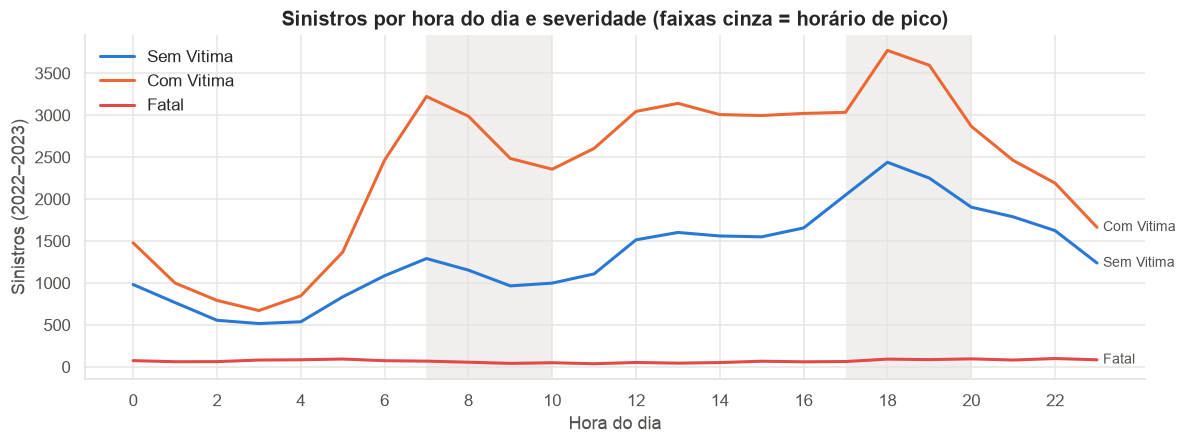

In [6]:
por_hora = (consolidado.groupby(["hora", "severidade"]).size().rename("sinistros").reset_index())
ordem_sev = ["SEM_VITIMA", "COM_VITIMA", "FATAL"]
fig, ax = plt.subplots(figsize=(11, 4.2))
for sev in ordem_sev:
    d = por_hora[por_hora.severidade == sev]
    ax.plot(d.hora, d.sinistros, lw=2, color=viz.COR_SEVERIDADE[sev], label=sev.replace("_", " ").title())
    ax.annotate(sev.replace("_", " ").title(), (23, d.sinistros.iloc[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", color=viz.TEXTO_SECUNDARIO, fontsize=9)
ax.axvspan(7, 10, color=viz.GRADE, alpha=.6, lw=0); ax.axvspan(17, 20, color=viz.GRADE, alpha=.6, lw=0)
ax.set(xlabel="Hora do dia", ylabel="Sinistros (2022–2023)", xticks=range(0, 24, 2),
       title="Sinistros por hora do dia e severidade (faixas cinza = horário de pico)")
ax.legend(frameon=False, loc="upper left"); plt.tight_layout(); plt.show()

**Interpretação.** Os sinistros seguem o ritmo da cidade: vale na madrugada (3–5 h), subida acentuada no pico da manhã e platô elevado das 12 h às 19 h, com máximo no pico da tarde. A curva de sinistros **com vítima** acompanha a de sem vítima, mas com proporção maior à noite e madrugada. Os **fatais** têm perfil próprio: relativamente achatado ao longo do dia e com peso maior entre 20 h e 6 h, quando há menos tráfego e mais velocidade — o que explica o FRT baixo da categoria.

### 3.2 Mapa de calor: dia da semana × hora

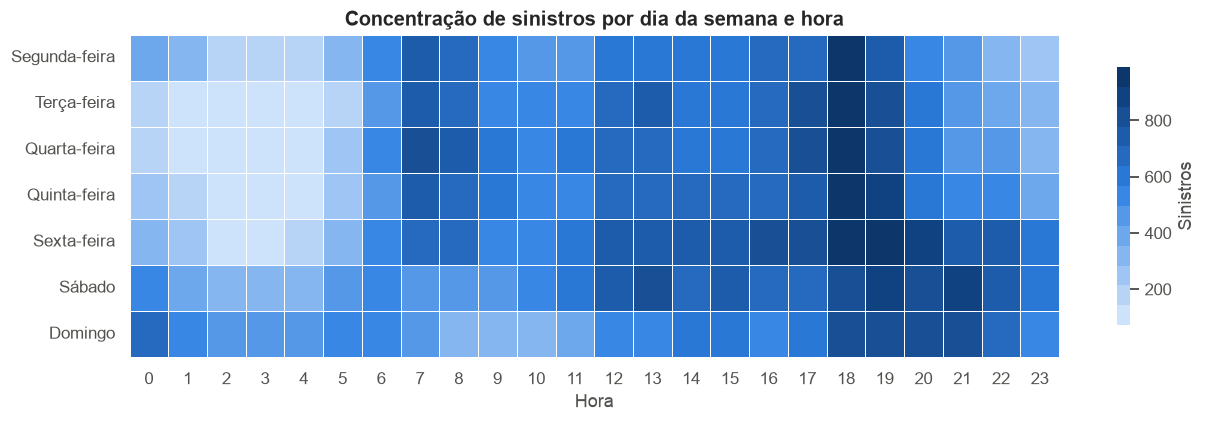

In [7]:
mapa = consolidado.pivot_table(index="dia_semana", columns="hora", values="id_sinistro", aggfunc="size").reindex(ORDEM_DIAS)
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(mapa, cmap=sns.color_palette(viz.SEQUENCIAL, as_cmap=True), linewidths=.5, linecolor="white",
            cbar_kws={"label": "Sinistros", "shrink": .8}, ax=ax)
ax.set(title="Concentração de sinistros por dia da semana e hora", xlabel="Hora", ylabel="")
plt.tight_layout(); plt.show()

**Interpretação.** Dias úteis mostram dois blocos quentes (7–9 h e 16–19 h), com a sexta-feira à tarde como o pior momento da semana. No fim de semana o padrão muda: sábado e domingo têm madrugadas mais carregadas (0–4 h) do que qualquer dia útil — assinatura de lazer noturno, álcool e vias vazias. Políticas de fiscalização têm, portanto, dois alvos distintos: congestionamento em dias úteis e velocidade/álcool nas madrugadas de fim de semana.

### 3.3 Lentidão ao longo do dia: dia útil × fim de semana/feriado

In [8]:
h = horario.dropna(subset=["km_lentidao_total"]).copy()
h["tipo_dia"] = np.where((h.fim_de_semana == 1) | (h.feriado == 1), "Fim de semana / feriado", "Dia útil")
perfil = h.groupby(["tipo_dia", "hora"]).km_lentidao_total.agg(media="mean", p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75)).reset_index()
fig = go.Figure()
for i, tipo in enumerate(["Dia útil", "Fim de semana / feriado"]):
    d = perfil[perfil.tipo_dia == tipo]
    cor = viz.CATEGORICAS[i]
    fig.add_trace(go.Scatter(x=pd.concat([d.hora, d.hora[::-1]]), y=pd.concat([d.p75, d.p25[::-1]]), fill="toself",
                             fillcolor=cor, opacity=.15, line=dict(width=0), hoverinfo="skip", showlegend=False))
    fig.add_trace(go.Scatter(x=d.hora, y=d.media, mode="lines", name=tipo, line=dict(color=cor, width=2),
                             hovertemplate="%{x}h: %{y:.1f} km<extra>" + tipo + "</extra>"))
fig.update_layout(**viz.PLOTLY_LAYOUT, title="Lentidão média por hora (faixa = quartis 25–75 %)",
                  xaxis_title="Hora do dia", yaxis_title="km de lentidão", hovermode="x unified", height=420)
fig.show()

**Interpretação.** Em dias úteis a lentidão tem a clássica forma bimodal. Nesta base o pico da manhã é o maior (média de ~44 km às 9 h, contra ~37 km às 18 h), com faixa interquartil larga nos dois picos: o congestionamento é muito sensível a eventos (chuva, sinistros, feriados emendados). Nos fins de semana e feriados a curva não passa de 6 km em nenhuma hora. Isso antecipa o que os modelos vão confirmar: **o calendário explica a maior parte da variância da lentidão**, e o clima atua como modulador.

Ressalva: a CET publica menos instantâneos à noite do que de manhã; parte da diferença entre os dois picos pode ser artefato de cobertura da coleta.

### 3.4 Chuva, frequência e severidade dos sinistros

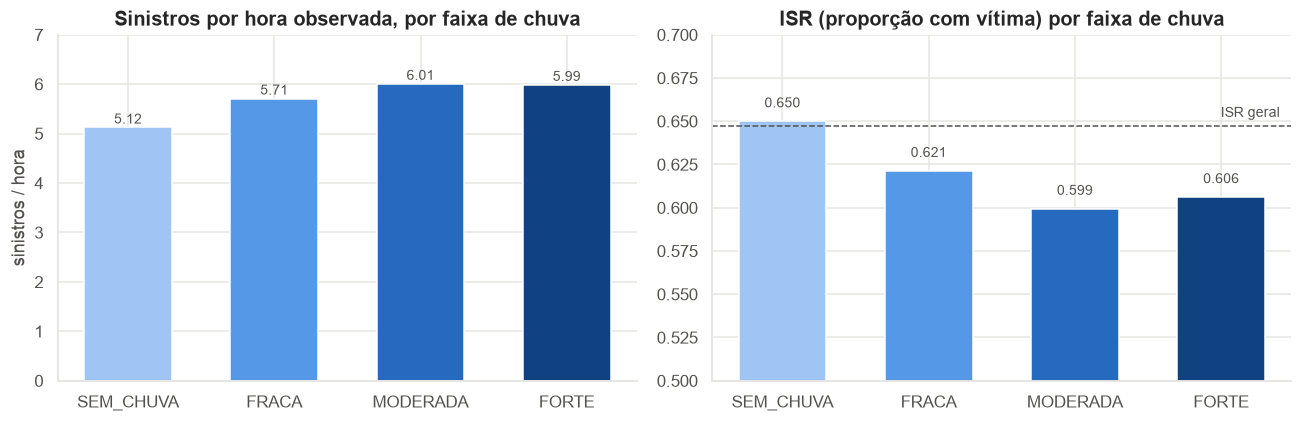

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cores = [viz.COR_CHUVA[f] for f in tsc.faixa_chuva]
axes[0].bar(tsc.faixa_chuva.astype(str), tsc.sinistros_por_hora, color=cores, width=.6)
for i, v in enumerate(tsc.sinistros_por_hora):
    axes[0].text(i, v + .08, f"{v:.2f}", ha="center", color=viz.TEXTO_SECUNDARIO, fontsize=9)
axes[0].set(title="Sinistros por hora observada, por faixa de chuva", ylabel="sinistros / hora", ylim=(0, 7))
axes[1].bar(tsc.faixa_chuva.astype(str), tsc.isr, color=cores, width=.6)
axes[1].axhline(kpis["isr_geral"], ls="--", lw=1, color=viz.TEXTO_SECUNDARIO)
axes[1].text(3.4, kpis["isr_geral"] + .005, "ISR geral", ha="right", fontsize=9, color=viz.TEXTO_SECUNDARIO)
for i, v in enumerate(tsc.isr):
    axes[1].text(i, v + .008, f"{v:.3f}", ha="center", color=viz.TEXTO_SECUNDARIO, fontsize=9)
axes[1].set(title="ISR (proporção com vítima) por faixa de chuva", ylim=(.5, .7))
for ax in axes: ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Interpretação.** Os dois painéis contam a história completa. À esquerda, a **frequência** cresce monotonicamente com a intensidade da chuva (+11 % na chuva fraca, +17 % na moderada/forte). À direita, a **proporção com vítima** cai sob chuva. Em outras palavras: chove, batem mais, mas batem "mais devagar". O efeito líquido em vítimas por hora ainda é positivo (3,33 → 3,63 vítimas-sinistro/hora), então a chuva continua sendo um fator de risco agregado, só que por volume e não por gravidade.

Ressalva de medida: as faixas MODERADA e FORTE somam apenas ~310 horas em dois anos; o intervalo de confiança do ISR nessas faixas é largo (± 0,05).

### 3.5 ISR por categoria de via e condição de chuva

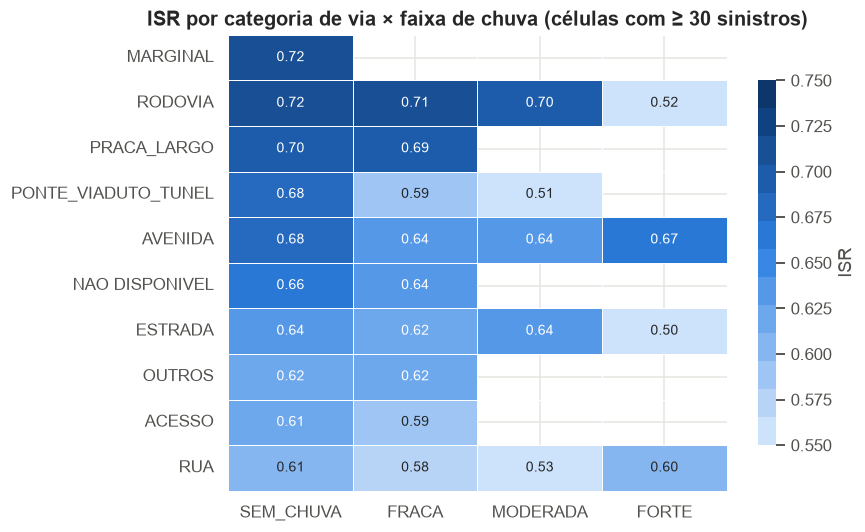

In [10]:
isr_mapa = calcular_isr(consolidado, minimo_sinistros=30).pivot(index="categoria_via", columns="faixa_chuva", values="isr").reindex(columns=ORDEM_CHUVA)
isr_mapa = isr_mapa.loc[isr_mapa["SEM_CHUVA"].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(isr_mapa, annot=True, fmt=".2f", cmap=sns.color_palette(viz.SEQUENCIAL, as_cmap=True), vmin=.55, vmax=.75,
            linewidths=.5, linecolor="white", cbar_kws={"label": "ISR", "shrink": .8}, ax=ax,
            annot_kws={"size": 9})
ax.set(title="ISR por categoria de via × faixa de chuva (células com ≥ 30 sinistros)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

**Interpretação.** A dimensão **via** separa mais do que a dimensão **chuva**: rodovias e marginais têm ISR ≈ 0,72, enquanto ruas locais ficam em ≈ 0,61. A diferença de 11 pontos percentuais entre tipos de via é maior do que qualquer variação causada pela chuva dentro de uma mesma via. Para o poder público, isso sugere que a prioridade em redução de severidade está na **velocidade praticada** (rodovias, marginais, avenidas de trânsito rápido) e não em alertas meteorológicos.

### 3.6 Fator de Retenção de Tráfego por tipo de sinistro

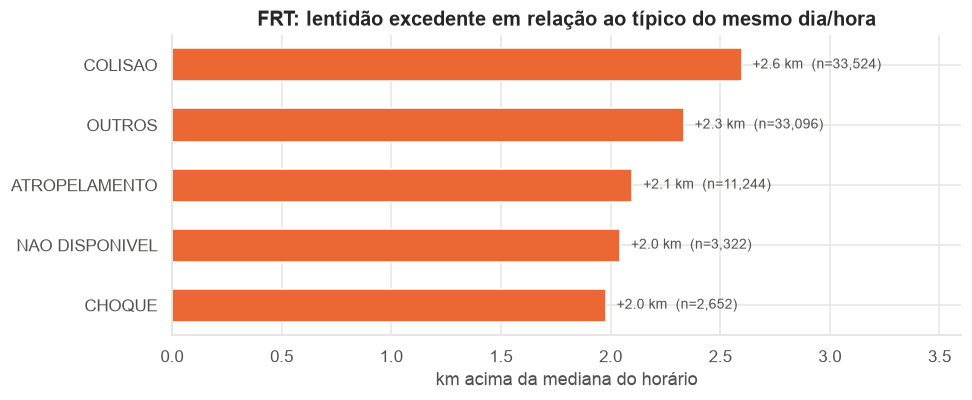

In [11]:
frt_plot = frt.sort_values("excedente_km")
fig, ax = plt.subplots(figsize=(9, 3.8))
cores = [viz.CATEGORICAS[1] if v > 0 else viz.CATEGORICAS[0] for v in frt_plot.excedente_km]
ax.barh(frt_plot.tp_sinistro_primario, frt_plot.excedente_km, color=cores, height=.55)
for i, (v, n) in enumerate(zip(frt_plot.excedente_km, frt_plot.total_sinistros)):
    ax.text(v + .05, i, f"+{v:.1f} km  (n={n:,})", va="center", fontsize=9, color=viz.TEXTO_SECUNDARIO)
ax.set(title="FRT: lentidão excedente em relação ao típico do mesmo dia/hora", xlabel="km acima da mediana do horário", xlim=(0, 3.6))
plt.tight_layout(); plt.show()

**Interpretação.** Todas as categorias ocorrem em horas com lentidão **acima** da mediana do seu horário, de +2,0 a +2,6 km (13–16 %). A leitura causal é limitada: o excedente mistura (i) o sinistro gerar fila e (ii) sinistros serem mais prováveis em horas já congestionadas. Ainda assim, colisões lideram em volume e em excedente absoluto, o que as torna o alvo natural de resposta rápida (remoção de veículos, sinalização) para mitigar retenção.

### 3.7 Lentidão e chuva no horário de pico

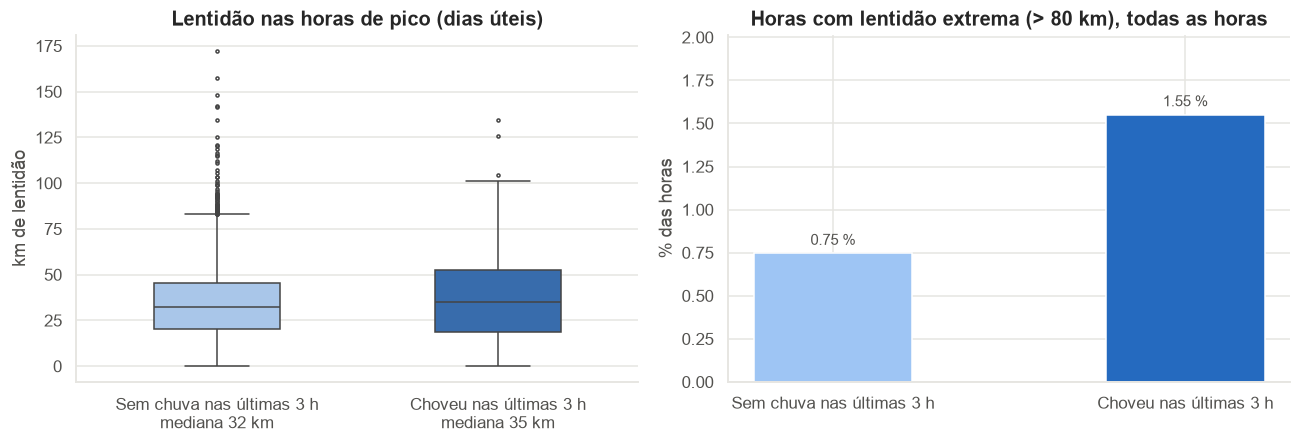

                           horas  mediana_km  media_km  excedente_medio_km
chuva_3h_rotulo                                                           
Choveu nas últimas 3 h       441        35.0      37.5                 5.5
Sem chuva nas últimas 3 h   2449        32.5      34.3                 1.9


In [12]:
# Controle pelo horário: comparamos cada hora com a mediana do mesmo dia da semana e hora.
hh = horario.dropna(subset=["km_lentidao_total", "chuva_3h"]).copy()
tipica = hh.groupby(["dia_semana_num", "hora"]).km_lentidao_total.transform("median")
hh["excedente_km"] = hh.km_lentidao_total - tipica
hh["chuva_3h_rotulo"] = np.where(hh.chuva_3h == 1, "Choveu nas últimas 3 h", "Sem chuva nas últimas 3 h")
pico = hh[hh.hora_pico == 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ordem = ["Sem chuva nas últimas 3 h", "Choveu nas últimas 3 h"]
cores = [viz.COR_CHUVA["SEM_CHUVA"], viz.COR_CHUVA["MODERADA"]]
sns.boxplot(data=pico, x="chuva_3h_rotulo", y="km_lentidao_total", order=ordem, palette=cores, width=.45, fliersize=2, linewidth=1, ax=axes[0])
med = pico.groupby("chuva_3h_rotulo").km_lentidao_total.median()
axes[0].set_xticks(range(len(ordem)), [f"{r}\nmediana {med[r]:.0f} km" for r in ordem])
axes[0].set(title="Lentidão nas horas de pico (dias úteis)", xlabel="", ylabel="km de lentidão")

extremo = hh.assign(extrema=hh.km_lentidao_total > 80).groupby("chuva_3h_rotulo").extrema.mean().reindex(ordem) * 100
axes[1].bar(ordem, extremo.values, color=cores, width=.45)
for i, v in enumerate(extremo.values):
    axes[1].text(i, v + .05, f"{v:.2f} %", ha="center", fontsize=10, color=viz.TEXTO_SECUNDARIO)
axes[1].set(title="Horas com lentidão extrema (> 80 km), todas as horas", ylabel="% das horas", ylim=(0, extremo.max() * 1.3))
plt.tight_layout(); plt.show()
print(pico.groupby("chuva_3h_rotulo").agg(horas=("km_lentidao_total", "size"), mediana_km=("km_lentidao_total", "median"),
      media_km=("km_lentidao_total", "mean"), excedente_medio_km=("excedente_km", "mean")).round(1))

**Interpretação.** Mantendo o horário fixo (só picos de dias úteis), a chuva recente desloca a distribuição para cima de forma **moderada**: a mediana sobe de ~32 km para ~35 km (+8 %) e o excedente médio em relação ao típico do horário vai de +1,8 km para +5,4 km. O efeito mais relevante está na cauda: horas com lentidão extrema (> 80 km) são quase **duas vezes mais frequentes** quando choveu nas últimas 3 h. Ou seja, a chuva raramente muda um dia comum, mas é um ingrediente frequente dos dias caóticos. Usamos a chuva acumulada em 3 h (e não a da hora exata) porque o alagamento e a redução de velocidade persistem depois que a chuva para.

Ressalva: a estação do Mirante de Santana está na zona norte; pancadas localizadas em outras regiões não aparecem no sensor e diluem o efeito medido.

### 3.8 Tendência mensal

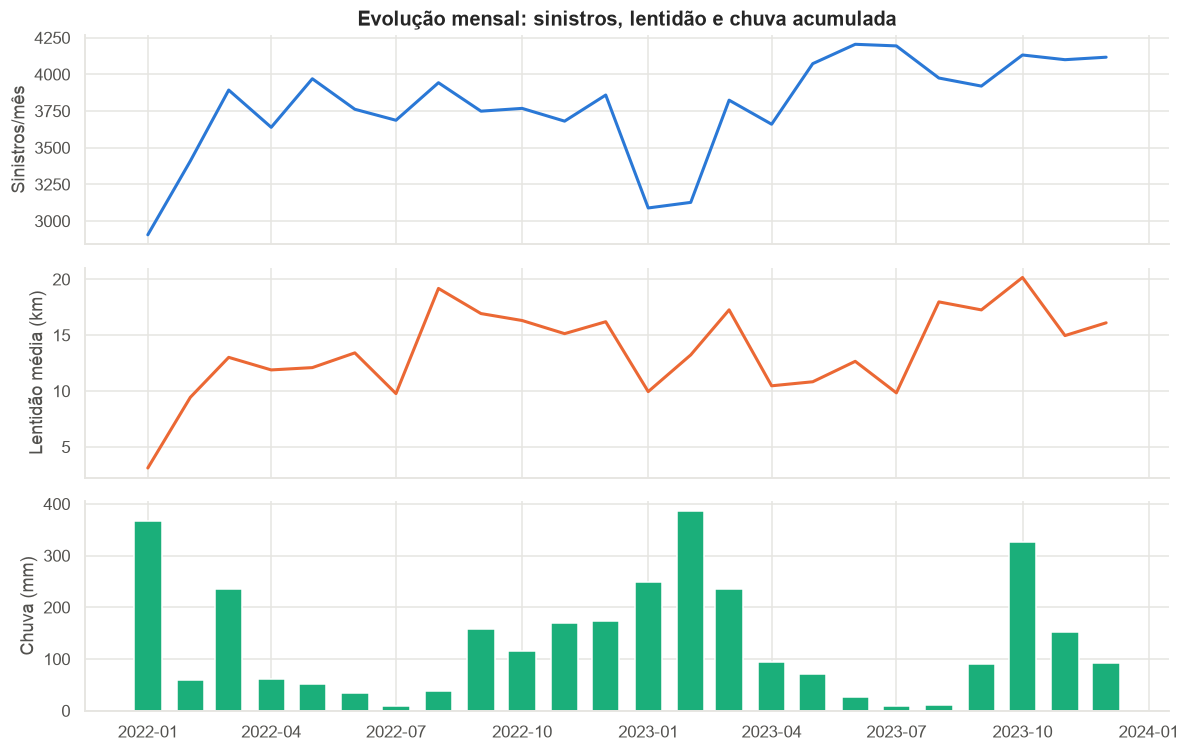

In [13]:
mensal = horario.assign(mes_ref=horario.datetime.dt.to_period("M").dt.to_timestamp()).groupby("mes_ref").agg(
    sinistros=("n_sinistros", "sum"), lentidao_media_km=("km_lentidao_total", "mean"), chuva_mm=("precipitacao_mm", "sum")).reset_index()
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(mensal.mes_ref, mensal.sinistros, color=viz.CATEGORICAS[0], lw=2); axes[0].set_ylabel("Sinistros/mês")
axes[1].plot(mensal.mes_ref, mensal.lentidao_media_km, color=viz.CATEGORICAS[1], lw=2); axes[1].set_ylabel("Lentidão média (km)")
axes[2].bar(mensal.mes_ref, mensal.chuva_mm, color=viz.CATEGORICAS[2], width=20); axes[2].set_ylabel("Chuva (mm)")
axes[0].set_title("Evolução mensal: sinistros, lentidão e chuva acumulada"); plt.tight_layout(); plt.show()

**Interpretação.** Os três painéis compartilham o eixo do tempo mas não a escala (evitamos eixos duplos). Sinistros e lentidão têm sazonalidade parecida: queda em janeiro/fevereiro e em julho (férias escolares), com 2023 acima de 2022 em ambas as séries (+5 % de sinistros, +8 % de lentidão média). A chuva concentra-se no verão (outubro a março) e não explica sozinha os picos de lentidão, que ocorrem em agosto, outubro e março — reforço de que o calendário domina, enquanto a chuva amplifica. O valor muito baixo de lentidão em janeiro de 2022 (3 km) sugere cobertura parcial da coleta da CET no início da série.

## 4. Modelagem preditiva

Dois modelos foram treinados em `src/modeling.py` e salvos em `.pkl` na raiz:

| Modelo | Alvo | Algoritmo | Baseline |
|---|---|---|---|
| Classificação | `com_vitima` (sinistro terá vítima?) | XGBClassifier, classes balanceadas | Regressão logística |
| Regressão | `km_lentidao_total` (lentidão da hora) | XGBRegressor | Ridge |

**Protocolo:** split 80/20 (estratificado na classificação) → validação cruzada 5-fold **apenas no treino** → métricas finais no teste intocado → verificação temporal extra (treina 2022, testa 2023). Aqui carregamos o metadata com as métricas e reproduzimos o split (mesma semente) para inspecionar previsões.

In [14]:
meta = carregar_metadata()
def tabela_metricas(bloco, chaves):
    linhas = {}
    linhas["CV 5-fold (treino)"] = {k: bloco["metricas_cv"].get(k, {}).get("media", np.nan) for k in chaves}
    linhas["Teste (holdout)"] = {k: bloco["metricas_teste"].get(k, np.nan) for k in chaves}
    linhas["Baseline (teste)"] = {k: bloco["baseline_teste"].get(k, np.nan) for k in chaves}
    linhas["Temporal (treina 2022 → testa 2023)"] = {k: bloco["metricas_temporal"].get(k, np.nan) for k in chaves}
    return pd.DataFrame(linhas).T
print("Classificação de severidade — n_treino =", meta["classificacao"]["n_treino"], "| n_teste =", meta["classificacao"]["n_teste"])
display(tabela_metricas(meta["classificacao"], ["f1", "f1_macro", "roc_auc", "balanced_accuracy", "precision", "recall"]).round(3))
print("Regressão de lentidão — n_treino =", meta["regressao"]["n_treino"], "| n_teste =", meta["regressao"]["n_teste"])
display(tabela_metricas(meta["regressao"], ["rmse", "mae", "r2"]).round(3))

Classificação de severidade — n_treino = 70076 | n_teste = 17519


,f1,f1_macro,roc_auc,balanced_accuracy,precision,recall
CV 5-fold (treino),0.654,0.562,0.598,0.569,NaN,NaN
Teste (holdout),0.657,0.565,0.599,0.572,0.705,0.615
Baseline (teste),0.636,0.556,0.591,0.566,0.703,0.581
Temporal (treina 2022 → testa 2023),0.657,0.548,0.576,0.552,0.693,0.625


Regressão de lentidão — n_treino = 12466 | n_teste = 3117


,rmse,mae,r2
CV 5-fold (treino),10.127,5.999,0.715
Teste (holdout),9.611,5.774,0.734
Baseline (teste),14.010,9.392,0.436
Temporal (treina 2022 → testa 2023),12.546,7.537,0.504


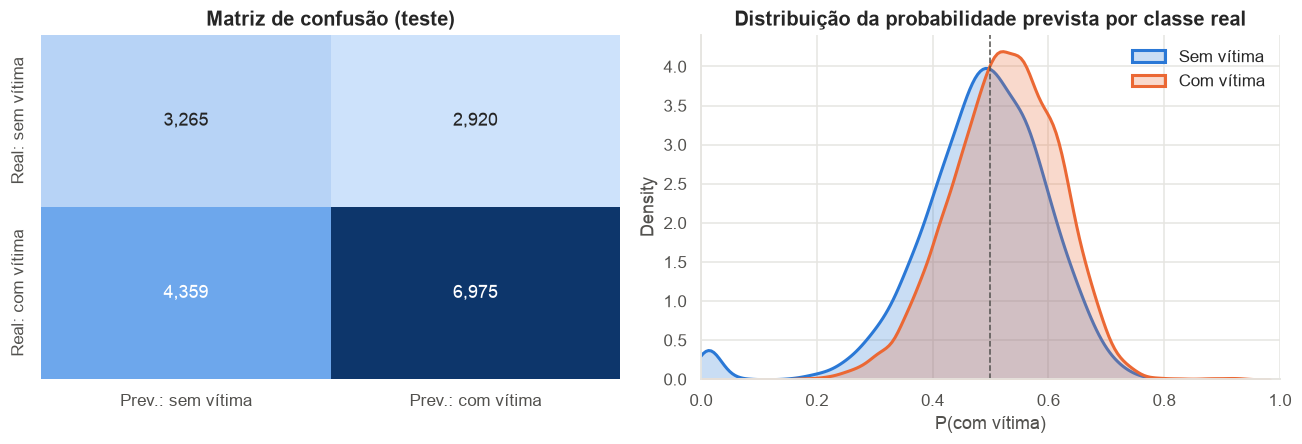

In [15]:
from sklearn.model_selection import train_test_split
clf = carregar_modelo(config.MODELO_CLASSIFICACAO_PKL)
Xc, yc = preparar_dados_classificacao(carregar_consolidado())
_, Xc_te, _, yc_te = train_test_split(Xc, yc, test_size=TEST_SIZE, stratify=yc, random_state=config.RANDOM_STATE)
proba = clf.predict_proba(Xc_te)[:, 1]
cm = np.array(meta["classificacao"]["metricas_teste"]["matriz_confusao"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(cm, annot=True, fmt=",d", cmap=sns.color_palette(viz.SEQUENCIAL, as_cmap=True), cbar=False, ax=axes[0],
            xticklabels=["Prev.: sem vítima", "Prev.: com vítima"], yticklabels=["Real: sem vítima", "Real: com vítima"], annot_kws={"size": 12})
axes[0].set_title("Matriz de confusão (teste)")
for i, (lab, cor) in enumerate([("Sem vítima", viz.COR_SEVERIDADE["SEM_VITIMA"]), ("Com vítima", viz.COR_SEVERIDADE["COM_VITIMA"])]):
    sns.kdeplot(proba[yc_te.values == i], color=cor, fill=True, alpha=.25, lw=2, label=lab, ax=axes[1])
axes[1].axvline(.5, ls="--", color=viz.TEXTO_SECUNDARIO, lw=1); axes[1].legend(frameon=False)
axes[1].set(title="Distribuição da probabilidade prevista por classe real", xlabel="P(com vítima)", xlim=(0, 1))
plt.tight_layout(); plt.show()

**Análise crítica — classificação.** O modelo tem poder discriminativo **limitado**: ROC-AUC ≈ 0,60 no teste e 0,58 na validação temporal; acurácia balanceada de 0,57 contra 0,50 de um chute aleatório. A validação cruzada tem desvio-padrão pequeno (< 0,01), então o resultado é estável — o problema não é variância, é **sinal**. As distribuições de probabilidade das duas classes se sobrepõem quase totalmente.

Por que isso é esperado e, em certo sentido, honesto:

1. **Restringimos deliberadamente as variáveis** a clima, tempo e via, como pede o enunciado. As variáveis que mais determinam vítimas (tipo de sinistro — atropelamento quase sempre tem vítima —, veículos envolvidos, presença de moto) foram excluídas porque só são conhecidas *depois* do sinistro e tornariam o modelo trivial e inútil como simulador "antes do fato".
2. Sem o balanceamento (`scale_pos_weight`), o XGBoost colapsava em "sempre com vítima", com F1 de 0,79 mas acurácia balanceada de 0,53 — F1 alto e enganoso. Preferimos o modelo balanceado, que erra mais na classe majoritária mas **acerta 53 % dos sinistros sem vítima** em vez de 9 %.
3. A feature mais importante é `tipo_via = NAO DISPONIVEL` (ISR de apenas 0,13): registros com via desconhecida são notificações incompletas sem vítima. É um **viés de registro**, não um fenômeno de trânsito, e deve ser lido como tal.

Uso recomendado: ranking relativo de risco (ex.: "rodovia à noite com chuva" vs "rua local à tarde"), nunca decisão individual.

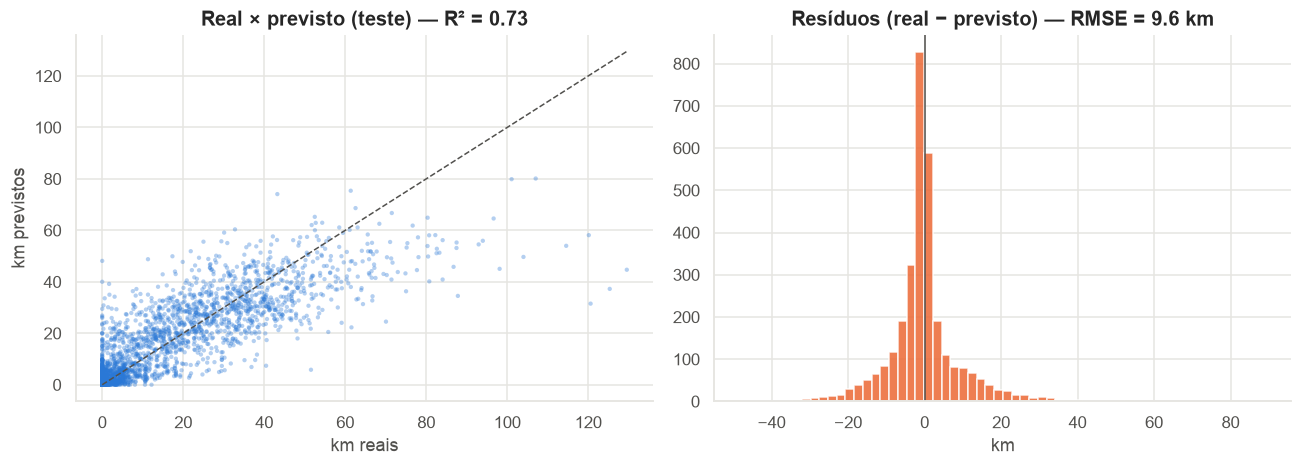

In [16]:
reg = carregar_modelo(config.MODELO_REGRESSAO_PKL)
Xr, yr = preparar_dados_regressao(carregar_horario())
_, Xr_te, _, yr_te = train_test_split(Xr, yr, test_size=TEST_SIZE, random_state=config.RANDOM_STATE)
pred = np.clip(reg.predict(Xr_te), 0, None)
residuo = yr_te.values - pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
axes[0].scatter(yr_te, pred, s=8, alpha=.35, color=viz.CATEGORICAS[0], edgecolor="none")
lim = max(yr_te.max(), pred.max()); axes[0].plot([0, lim], [0, lim], ls="--", lw=1, color=viz.TEXTO_SECUNDARIO)
axes[0].set(title=f"Real × previsto (teste) — R² = {meta['regressao']['metricas_teste']['r2']:.2f}", xlabel="km reais", ylabel="km previstos")
axes[1].hist(residuo, bins=60, color=viz.CATEGORICAS[1], alpha=.85)
axes[1].axvline(0, color=viz.TEXTO_SECUNDARIO, lw=1)
axes[1].set(title=f"Resíduos (real − previsto) — RMSE = {meta['regressao']['metricas_teste']['rmse']:.1f} km", xlabel="km")
plt.tight_layout(); plt.show()

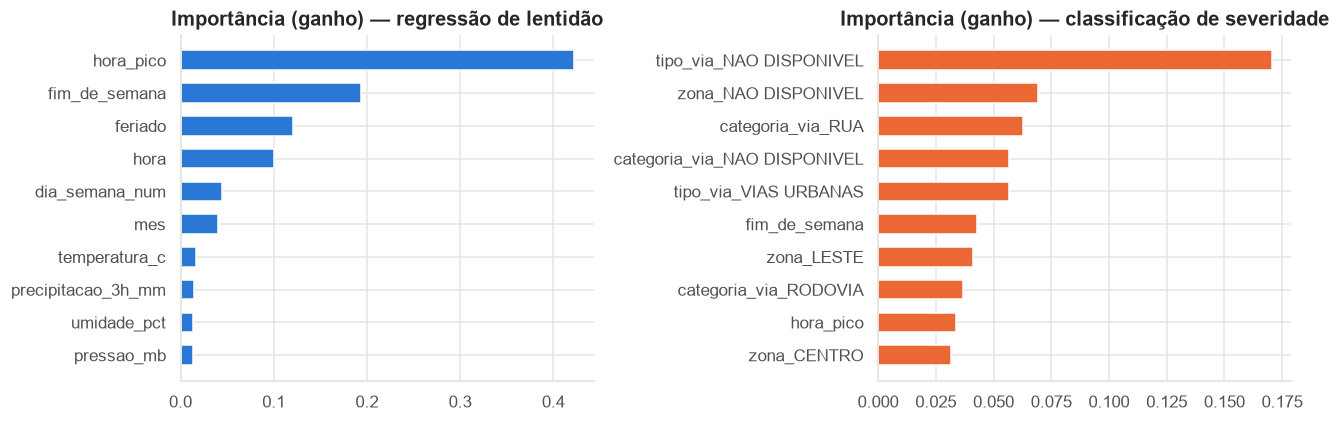

In [17]:
imp = pd.Series(meta["regressao"]["importancia_features"]).sort_values().tail(10)
imp_c = pd.Series(meta["classificacao"]["importancia_features"]).sort_values().tail(10)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(imp.index, imp.values, color=viz.CATEGORICAS[0], height=.6); axes[0].set_title("Importância (ganho) — regressão de lentidão")
axes[1].barh(imp_c.index, imp_c.values, color=viz.CATEGORICAS[1], height=.6); axes[1].set_title("Importância (ganho) — classificação de severidade")
plt.tight_layout(); plt.show()

**Análise crítica — regressão.** O regressor explica **73 % da variância** da lentidão horária no teste (RMSE 9,6 km sobre uma média de 13,6 km) e supera com folga o baseline linear (R² 0,44): a relação entre hora do dia e congestionamento é fortemente não linear, e as árvores capturam as interações hora × dia útil × feriado. Na validação temporal (treina 2022, testa 2023) o R² cai para 0,50 — há deriva: 2023 teve lentidão média 5 % maior e dias atípicos (greves, eventos) que o calendário não codifica.

O gráfico de resíduos é assimétrico: o modelo **subestima as horas extremas** (acima de 80 km), justamente as que mais importam operacionalmente. Isso é esperado com o erro quadrático e poucas observações na cauda.

As importâncias confirmam a EDA: `hora_pico`, `fim_de_semana`, `feriado` e `hora` respondem por mais de 85 % do ganho; as variáveis climáticas aparecem depois (temperatura e chuva acumulada em 3 h). O clima **não é irrelevante** — na seção 3.7 a chuva recente elevou a mediana do pico em ~8 % e dobrou a frequência de horas extremas — mas, numa grade de 17 mil horas em que só 8 % têm chuva, seu peso global é pequeno.

**Limitações comuns aos dois modelos**

* Uma única estação meteorológica (Mirante de Santana, zona norte) representa toda a cidade; chuvas convectivas de verão são localizadas e podem não aparecer no sensor.
* A lentidão da CET é agregada à cidade inteira; o simulador não distingue corredores.
* Validação cruzada aleatória em dados horários superestima o desempenho (horas vizinhas são correlacionadas); por isso reportamos também a validação temporal, que deve ser lida como a estimativa conservadora.
* Dois anos de histórico não cobrem anos atípicos (pandemia em 2020–21 ficou de fora por não haver lentidão disponível).

## 5. Conclusões

1. **O calendário manda no congestionamento; o clima modula.** Hora, dia útil e feriado explicam a maior parte da lentidão. A chuva recente eleva a mediana do pico em ~8 % e quase dobra a chance de uma hora extrema (> 80 km).
2. **Chuva aumenta a frequência de sinistros (+17 %), mas não a sua gravidade.** A proporção com vítima cai levemente sob chuva, provavelmente porque colisões em baixa velocidade dominam.
3. **A via é o maior determinante de severidade.** Rodovias e marginais têm ISR ≈ 0,72; ruas locais ≈ 0,61. Políticas de redução de velocidade têm mais alavancagem que alertas meteorológicos.
4. **Sinistros fatais têm perfil próprio:** madrugada, fim de semana, baixa lentidão — fiscalização de velocidade e álcool é o instrumento adequado.
5. **O modelo de lentidão é utilizável** (R² 0,73; 0,50 fora do período) para planejamento de operação; o de severidade serve para ranking relativo de risco, não para previsão individual.

Recomendações detalhadas para o poder público, incluindo discussão de vieses, estão na aba *Recomendações* do dashboard Streamlit (`app/main.py`).